# Predicting demographics & personality from music ratings

**Predictors:** each participant's liking ratings (1–7) of the **320 clips that every participant heard**.

**Targets:** gender, race, age, area grew up in, lyrics-vs-instruments, music importance, religion,
political view, SES (prescreen survey) and the Big Five personality scores (BFI-44, from the DB).

**Models:** LightGBM (no L1, no row sampling, trees chosen by early stopping). Clips are selected by
recursive feature elimination with a fixed LightGBM setting, then the final model's hyperparameters are tuned
with Optuna (TPE, Bayesian optimization). Selection and tuning run inside each cross-validation training fold
(nested), so held-out scores are honest. Categorical targets: balanced accuracy vs chance = 1/k.
Continuous targets: R². Performance is out-of-fold, 5-fold × 3 repeats.

In [1]:
import numpy as np, pandas as pd, sqlite3, warnings
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from lightgbm import LGBMClassifier, LGBMRegressor
from sklearn.feature_selection import RFECV
from sklearn.metrics import balanced_accuracy_score, r2_score
from sklearn.model_selection import RepeatedStratifiedKFold, RepeatedKFold, StratifiedKFold, KFold
warnings.filterwarnings('ignore')

conn = sqlite3.connect("machine2_new_aug.db")
XLS = "Music preference prescreening survey.xlsx"
MIN_RATED = 250   # participant must have rated >= 250 of the 320 core clips
MIN_CELL = 10    # categorical levels with fewer matched participants are dropped
SEED = 42

In [2]:
%pip install lightgbm optuna

Note: you may need to restart the kernel to use updated packages.


## 1. The 320 core clips
Clips presented to all participants exactly once (clip 1000 is presented ~12× as an exposure
manipulation and is excluded).

In [3]:
n_part = pd.read_sql_query("SELECT COUNT(DISTINCT participantId) n FROM music", conn).n[0]
core = pd.read_sql_query(f'''
    SELECT instanceId FROM music
    GROUP BY instanceId
    HAVING COUNT(DISTINCT participantId) = {n_part} AND COUNT(*) = {n_part}
''', conn).instanceId.tolist()
print(len(core), "core clips")

ratings = pd.read_sql_query(f'''
    SELECT participantId, instanceId, rating FROM music
    WHERE rating IS NOT NULL AND instanceId IN ({",".join(map(str, core))})
''', conn)
X = ratings.pivot_table(index='participantId', columns='instanceId', values='rating')
X = X[X.notna().sum(axis=1) >= MIN_RATED]
X = X.fillna(X.mean())                      # the few missing ratings -> clip mean
print("rating matrix:", X.shape)

320 core clips


rating matrix: (959, 320)


In [4]:
mu = pd.read_sql_query(f'''
    SELECT *
    FROM music
''', conn)

In [5]:
mu

,participantId,trialNumber,taskId,instanceId,familiarity,rating,arousal,joy,nostalgia,groove,...,anxiety,disgust,anger,no_emotion,reflection,boredom,rating_reaction_time,familiarity_reaction_time,arousal_reaction_time,emotion_reaction_time
0,97f4_7385706431,2,0,308,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,97f4_7385706431,4,0,41,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,97f4_7385706431,6,0,142,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,97f4_7385706431,8,0,265,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,97f4_7385706431,10,0,103,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
428795,zzru_7377077714,792,0,123,5.0,5.0,5.0,0.0,1.0,0.0,...,0.0,0.0,0.0,1.0,1.0,0.0,1.984,3.031,3.983,7.808
428796,zzru_7377077714,794,0,186,1.0,3.0,4.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,2.181,3.996,4.932,7.589
428797,zzru_7377077714,796,0,37,3.0,5.0,3.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.949,2.716,4.452,7.605
428798,zzru_7377077714,798,0,267,1.0,4.0,4.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,2.660,4.187,5.211,7.164


## 2. Personality (BFI-44)
`agreement_level` is stored with mixed SQLite types: most answers are integers, but ~7% are single raw bytes (`b'\x05'` = 5), which are decoded here. `-1` means no response.

In [6]:
bfi = pd.read_sql_query('''
    SELECT participantId, instanceId, agreement_level AS v FROM personality
''', conn)
# ~7% of answers are stored as a raw byte (e.g. b'\x05' = 5); CAST(... AS INTEGER) would turn them into 0
bfi['v'] = bfi.v.map(lambda v: int.from_bytes(v, 'little') if isinstance(v, bytes) else v).astype(float)
bfi.loc[bfi.v < 0, 'v'] = np.nan
assert bfi.v.dropna().between(1, 5).all()
bfi = bfi.pivot_table(index='participantId', columns='instanceId', values='v')
REV = [2, 6, 8, 9, 12, 18, 21, 23, 24, 27, 31, 34, 35, 37, 41, 43]
bfi[REV] = 6 - bfi[REV]
SCALES = {'Extraversion': [1, 6, 11, 16, 21, 26, 31, 36],
          'Agreeableness': [2, 7, 12, 17, 22, 27, 32, 37, 42],
          'Conscientiousness': [3, 8, 13, 18, 23, 28, 33, 38, 43],
          'Neuroticism': [4, 9, 14, 19, 24, 29, 34, 39],
          'Openness': [5, 10, 15, 20, 25, 30, 35, 40, 41, 44]}
big5 = pd.DataFrame({k: bfi[v].mean(axis=1) for k, v in SCALES.items()})
big5.describe().round(2)

,Extraversion,Agreeableness,Conscientiousness,Neuroticism,Openness
count,1032.00,1036.00,1028.00,1030.00,1038.00
mean,3.07,3.68,3.35,3.37,3.81
std,0.85,0.65,0.69,0.76,0.61
min,1.00,1.00,1.00,1.12,1.00
25%,2.38,3.22,2.89,2.88,3.40
50%,3.12,3.67,3.33,3.38,3.80
75%,3.62,4.11,3.89,3.88,4.30
max,5.00,5.00,5.00,5.00,5.00


## 3. Prescreen survey, joined on the 4-character code
The Excel file has a two-row header. Codes that appear more than once in the Excel, or 4-char
prefixes shared by several DB participants, are ambiguous and dropped.

In [7]:
raw = pd.read_excel(XLS, header=None).astype(object)
survey = raw.iloc[2:].reset_index(drop=True)
survey['code'] = survey[9].map(lambda s: str(s).strip().lower())
survey = survey[~survey.code.duplicated(keep=False)].set_index('code')

prefix = pd.Series(X.index.str[:4].str.lower(), index=X.index)
prefix = prefix[~prefix.duplicated(keep=False)]
prefix = prefix[prefix.isin(survey.index)]
S = survey.loc[prefix.values].set_index(prefix.index)
print(f"{len(S)} participants matched 1:1 between the DB and the survey")

def txt(col):
    return S[col].map(lambda v: v.strip() if isinstance(v, str) and v.strip() else np.nan)

# survey column index -> target
survey_targets = {
    'gender':                txt(131).where(txt(131).isin(['Male', 'Female'])),
    'race':                  txt(134),
    'age':                   pd.to_numeric(S[133], errors='coerce'),
    'area':                  txt(137).where(txt(137).isin(['Urban', 'Suburban', 'Rural'])),
    'lyrics_vs_instruments': txt(56),
    'music_importance':      txt(55),
    'religion':              txt(111),
    'political_view':        txt(108),
    'SES':                   txt(136).where(txt(136) != 'Prefer not to disclose'),
}

797 participants matched 1:1 between the DB and the survey


## 4. Targets

In [8]:
targets, kinds, dropped = {}, {}, {}
for name, y in survey_targets.items():
    if name == 'age':
        targets[name], kinds[name] = y.astype(float), 'reg'
        continue
    counts = y.value_counts()
    dropped[name] = counts[counts < MIN_CELL].to_dict()
    targets[name] = y.where(y.isin(counts[counts >= MIN_CELL].index))
    kinds[name] = 'clf'
for k in SCALES:
    targets[f'BFI_{k}'], kinds[f'BFI_{k}'] = big5[k], 'reg'

for name, y in targets.items():
    y = y.reindex(X.index).dropna()
    if kinds[name] == 'clf':
        print(f"{name:22s} n={len(y):4d}  levels: {y.value_counts().to_dict()}")
        if dropped[name]: print(f"{'':22s} dropped (<{MIN_CELL}): {dropped[name]}")
    else:
        print(f"{name:22s} n={len(y):4d}  mean={y.mean():.2f} sd={y.std():.2f}")

gender                 n= 766  levels: {'Female': 527, 'Male': 239}
race                   n= 794  levels: {'Asian': 319, 'White': 186, 'Hispanic': 138, 'Black': 84, 'Prefer to self-describe': 42, 'Middle Eastern': 14, 'Prefer not to disclose': 11}
age                    n= 796  mean=20.09 sd=3.60
area                   n= 773  levels: {'Suburban': 380, 'Urban': 358, 'Rural': 35}
lyrics_vs_instruments  n= 789  levels: {'Both are equally important to me': 513, 'Lyrics': 138, 'Instruments': 138}
music_importance       n= 790  levels: {'It plays a big role in my life': 547, 'It plays a small role in my life': 149, 'Music is my life': 94}
                       dropped (<10): {'It plays no role in my life': 4}
religion               n= 769  levels: {'Atheism/Agnosticism': 317, 'Christianity': 255, 'Other': 85, 'Judaism': 31, 'Buddhism': 28, 'Islam': 28, 'Hinduism': 25}
political_view         n= 782  levels: {'Liberal': 347, "I don't care": 135, 'Moderate': 110, 'Progressive': 90, 'Socialis

## 5. LightGBM: RFE feature selection + Optuna tuning

Inside every outer training fold (5-fold × 3 repeats):

1. **RFE with static parameters.** Starting from all 320 clips, a fixed LightGBM setting (`RFE_PARAMS`) is fit, and
   the least important clips (gain) are dropped along the path 320 → 256 → 192 → … → 5. Every fit early-stops on a validation split.
   An inner 3-fold CV scores each clip count; with `USE_ONE_SE` the smallest count within one SE of the best
   is kept. RFE is then rerun on the full training fold to get the clip set.
2. **Optuna (TPE) tunes the final model** on those clips: `learning_rate`, `num_leaves`, `min_child_samples`,
   `colsample_bytree`, `reg_lambda` (L2). Each trial is scored by inner 3-fold CV with early stopping; the
   median pruner stops weak trials early. The tree count is the mean early-stopped
   iteration of the best trial.
3. The final model is refit on the whole training fold and scored on the untouched outer fold.

No L1 penalty and no row sampling anywhere (`reg_alpha=0`, `subsample=1`).

In [9]:
import optuna
import lightgbm as lgb
from lightgbm import LGBMClassifier, LGBMRegressor
from joblib import Parallel, delayed
from sklearn.model_selection import (StratifiedKFold, KFold, RepeatedStratifiedKFold, RepeatedKFold,
                                     train_test_split)
from sklearn.metrics import balanced_accuracy_score, r2_score
optuna.logging.set_verbosity(optuna.logging.WARNING)

# ── Configuration ─────────────────────────────────────────────────────
# Every LightGBM fit here: no L1 (reg_alpha=0), no row sampling (subsample=1),
# fixed learning rate, and the number of trees chosen by early stopping.
LEARNING_RATE = 0.05         # used by RFE (static); Optuna tunes its own learning rate for the final model
MAX_TREES = 5000
EARLY_STOP = 50              # stop after 50 rounds without validation improvement

# Static LightGBM settings used only to rank clips during RFE
RFE_PARAMS = dict(num_leaves=15, min_child_samples=20, colsample_bytree=0.5, reg_lambda=1.0)
FEATURE_COUNTS = [320, 256, 192, 128, 96, 64, 48, 32, 24, 16, 12, 8, 5]   # RFE path, largest first
USE_ONE_SE = True            # prefer fewer clips when inner-CV score is within one SE of the best
ES_HOLDOUT = 0.15            # early-stopping holdout when running RFE on a whole training set

N_TRIALS = 40                # Optuna TPE trials for the final model's hyperparameters
INNER_SPLITS = 3
OUTER_SPLITS = 5
OUTER_REPEATS = 3
OUTER_N_JOBS = -1            # parallelize outer folds only; Optuna and LightGBM run single-threaded

FEATURE_NAMES = X.columns.to_numpy()


def make_model(kind, params, seed, n_estimators=MAX_TREES):
    base = dict(learning_rate=LEARNING_RATE, n_estimators=n_estimators, importance_type='gain',
                subsample=1.0, reg_alpha=0.0,              # no row sampling, no L1
                n_jobs=1, verbosity=-1, random_state=seed, force_col_wise=True)
    base.update(params)                                    # tuned values (incl. learning_rate) override defaults
    if kind == 'clf':
        return LGBMClassifier(class_weight='balanced', **base)
    return LGBMRegressor(**base)


def fit_es(kind, params, seed, X_fit, y_fit, X_val, y_val):
    m = make_model(kind, params, seed)
    m.fit(X_fit, y_fit, eval_X=X_val, eval_y=y_val,
          callbacks=[lgb.early_stopping(EARLY_STOP, verbose=False)])
    return m


def score_fn(kind):
    return balanced_accuracy_score if kind == 'clf' else r2_score


def inner_cv(kind, y, seed):
    cv = (StratifiedKFold(INNER_SPLITS, shuffle=True, random_state=seed) if kind == 'clf'
          else KFold(INNER_SPLITS, shuffle=True, random_state=seed))
    return list(cv.split(np.zeros(len(y)), y))


# ── Step 1: RFE with static parameters ────────────────────────────────
def rfe_path(kind, seed, X_fit, y_fit, X_val, y_val, counts):
    """Manual RFE (sklearn's RFE cannot early-stop): fit with early stopping, score on the
    validation rows, keep the top-k clips by gain for the next count.
    Returns {count: (validation score, selected column indices)}."""
    feats = np.arange(X_fit.shape[1])
    out = {}
    for i, k in enumerate(counts):
        m = fit_es(kind, RFE_PARAMS, seed, X_fit[:, feats], y_fit, X_val[:, feats], y_val)
        out[k] = (score_fn(kind)(y_val, m.predict(X_val[:, feats])), feats.copy())
        if i + 1 < len(counts):
            keep = np.argsort(m.feature_importances_)[::-1][:counts[i + 1]]
            feats = feats[np.sort(keep)]
    return out


def select_clips(kind, Xtr, ytr, seed):
    """Choose the clip count by inner CV over the RFE path, then run RFE on all training rows."""
    counts = [k for k in FEATURE_COUNTS if k <= Xtr.shape[1]]
    scores = np.array([[p[k][0] for k in counts]
                       for p in (rfe_path(kind, seed, Xtr[a], ytr[a], Xtr[b], ytr[b], counts)
                                 for a, b in inner_cv(kind, ytr, seed))])
    means, sds = scores.mean(0), scores.std(0)
    best = int(np.argmax(means))
    if USE_ONE_SE:
        eligible = np.flatnonzero(means >= means[best] - sds[best] / np.sqrt(INNER_SPLITS))
        best = int(eligible[np.argmin(np.array(counts)[eligible])])      # fewest clips among eligible
    k = counts[best]
    a, b = train_test_split(np.arange(len(ytr)), test_size=ES_HOLDOUT, random_state=seed,
                            stratify=ytr if kind == 'clf' else None)
    feats = rfe_path(kind, seed, Xtr[a], ytr[a], Xtr[b], ytr[b], [c for c in counts if c >= k])[k][1]
    return feats, k, dict(zip(counts, means))


# ── Step 2: Optuna (TPE) tunes the final model on the selected clips ──
def tune_final(kind, Xs, ytr, seed):
    optuna.logging.set_verbosity(optuna.logging.WARNING)      # also silence parallel workers
    splits = inner_cv(kind, ytr, seed + 1)

    def objective(trial):
        params = dict(
            learning_rate=trial.suggest_float('learning_rate', 0.005, 0.2, log=True),
            num_leaves=trial.suggest_int('num_leaves', 4, 64, log=True),
            min_child_samples=trial.suggest_int('min_child_samples', 5, 100, log=True),
            colsample_bytree=trial.suggest_float('colsample_bytree', 0.3, 1.0),
            reg_lambda=trial.suggest_float('reg_lambda', 1e-3, 30.0, log=True),
        )
        scores, trees = [], []
        for j, (a, b) in enumerate(splits):
            m = fit_es(kind, params, seed, Xs[a], ytr[a], Xs[b], ytr[b])
            scores.append(score_fn(kind)(ytr[b], m.predict(Xs[b])))
            trees.append(m.best_iteration_)
            trial.report(np.mean(scores), j)
            if trial.should_prune():
                raise optuna.TrialPruned()
        trial.set_user_attr('n_trees', int(np.mean(trees)))
        return float(np.mean(scores))

    study = optuna.create_study(direction='maximize',
                                sampler=optuna.samplers.TPESampler(seed=seed, n_startup_trials=10),
                                pruner=optuna.pruners.MedianPruner(n_startup_trials=10))
    study.optimize(objective, n_trials=N_TRIALS)
    return study.best_trial


def fit_pipeline(kind, Xtr, ytr, seed):
    feats, k, curve = select_clips(kind, Xtr, ytr, seed)
    best = tune_final(kind, Xtr[:, feats], ytr, seed)
    n_trees = max(best.user_attrs['n_trees'], 1)
    model = make_model(kind, best.params, seed, n_estimators=n_trees).fit(Xtr[:, feats], ytr)
    return dict(model=model, features=feats, count=k, curve=curve, params=best.params,
                n_trees=n_trees, inner_score=best.value)


# ── Nested evaluation ─────────────────────────────────────────────────
CLASSES = {}      # target -> class names, indexed by the integer codes used in fitting


def data_for(name):
    y = targets[name].reindex(X.index).dropna()
    Xn = X.loc[y.index].to_numpy(dtype=float)
    if kinds[name] == 'clf':
        CLASSES[name], yn = np.unique(y.to_numpy(dtype=str), return_inverse=True)   # int codes for LightGBM
        smallest = np.bincount(yn).min()
        if smallest < OUTER_SPLITS:      # one per outer fold; leaves >= 3 per outer-train for the inner split
            raise ValueError(f"{name}: smallest class has {smallest} rows; raise MIN_CELL "
                             f"(need >= {OUTER_SPLITS}).")
    else:
        yn = y.to_numpy(dtype=float)
    return Xn, yn


def outer_folds(name, yn):
    if kinds[name] == 'clf':
        return RepeatedStratifiedKFold(n_splits=OUTER_SPLITS, n_repeats=OUTER_REPEATS,
                                       random_state=SEED).split(yn, yn)
    return RepeatedKFold(n_splits=OUTER_SPLITS, n_repeats=OUTER_REPEATS, random_state=SEED).split(yn)


def target_seed(name):
    return SEED + 1000 * list(targets).index(name)          # different Optuna/LightGBM seed per target


def fold_job(name, Xn, yn, fold_id, tr, te):
    kind = kinds[name]
    fit = fit_pipeline(kind, Xn[tr], yn[tr], target_seed(name) + fold_id)   # selection + tuning on outer-train only
    pred = fit['model'].predict(Xn[te][:, fit['features']])
    proba = fit['model'].predict_proba(Xn[te][:, fit['features']]) if kind == 'clf' else None
    mask = np.zeros(Xn.shape[1], bool); mask[fit['features']] = True
    return dict(target=name, repeat=fold_id // OUTER_SPLITS + 1, fold=fold_id % OUTER_SPLITS + 1,
                score=score_fn(kind)(yn[te], pred), n_selected=fit['count'], selected_mask=mask,
                test_idx=te, pred=pred, proba=proba,                     # kept for the diagnostics in section 8
                n_trees=fit['n_trees'], best_params=fit['params'],
                inner_cv_score=fit['inner_score'])     # diagnostic only; report the OUTER score


DATA = {name: data_for(name) for name in targets}
jobs = [(name, Xn, yn, fold_id, tr, te)
        for name, (Xn, yn) in DATA.items()
        for fold_id, (tr, te) in enumerate(outer_folds(name, yn))]
print(f"{len(jobs)} outer folds; each: RFE ({INNER_SPLITS} inner folds x {len(FEATURE_COUNTS)} steps) "
      f"+ {N_TRIALS} Optuna trials x {INNER_SPLITS} inner folds")

fold_results = pd.DataFrame(Parallel(n_jobs=OUTER_N_JOBS, verbose=5)(delayed(fold_job)(*j) for j in jobs))


def summarise(name):
    d = fold_results.loc[fold_results.target == name]
    yn = DATA[name][1]
    clf = kinds[name] == 'clf'
    k = np.unique(yn).size if clf else np.nan
    return dict(target=name, metric='balanced accuracy' if clf else 'R2',
                score=d.score.mean(), sd=d.score.std(), chance=1 / k if clf else 0.0, k=k, n=len(yn),
                clips_selected_median=d.n_selected.median(),
                clips_selected_range=f"{d.n_selected.min()}-{d.n_selected.max()}",
                trees_median=d.n_trees.median())


results = pd.DataFrame([summarise(name) for name in targets])
results['above_chance'] = results.score - results.chance

# how often each clip survives selection across outer folds (clips never selected included)
selection_frequency = pd.concat(
    [pd.DataFrame({'target': name, 'clip': FEATURE_NAMES,
                   'selection_frequency': np.stack(d.selected_mask).mean(axis=0)})
     for name, d in fold_results.groupby('target', sort=False)],
    ignore_index=True).sort_values(['target', 'selection_frequency'], ascending=[True, False])

results.round(3)

210 outer folds; each: RFE (3 inner folds x 13 steps) + 40 Optuna trials x 3 inner folds


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 32 concurrent workers.


[Parallel(n_jobs=-1)]: Done   8 tasks      | elapsed:   22.9s


[Parallel(n_jobs=-1)]: Done  98 tasks      | elapsed:  4.1min


[Parallel(n_jobs=-1)]: Done 190 out of 210 | elapsed:  6.2min remaining:   39.1s


[Parallel(n_jobs=-1)]: Done 210 out of 210 | elapsed: 10.8min finished


,target,metric,score,sd,chance,k,n,clips_selected_median,clips_selected_range,trees_median,above_chance
0,gender,balanced accuracy,0.712,0.032,0.500,2.0,766,16.0,5-128,354.0,0.212
1,race,balanced accuracy,0.347,0.035,0.143,7.0,794,64.0,16-128,127.0,0.204
2,age,R2,0.081,0.194,0.000,NaN,796,16.0,5-128,161.0,0.081
3,area,balanced accuracy,0.415,0.048,0.333,3.0,773,16.0,5-256,319.0,0.081
4,lyrics_vs_instruments,balanced accuracy,0.424,0.035,0.333,3.0,789,12.0,5-32,91.0,0.091
5,music_importance,balanced accuracy,0.370,0.038,0.333,3.0,790,8.0,5-96,108.0,0.036
6,religion,balanced accuracy,0.274,0.045,0.143,7.0,769,8.0,5-32,333.0,0.131
7,political_view,balanced accuracy,0.221,0.045,0.143,7.0,782,48.0,5-320,449.0,0.078
8,SES,balanced accuracy,0.259,0.048,0.200,5.0,745,16.0,5-192,120.0,0.059
9,BFI_Extraversion,R2,0.031,0.040,0.000,NaN,959,24.0,5-96,56.0,0.031


## 6. Results

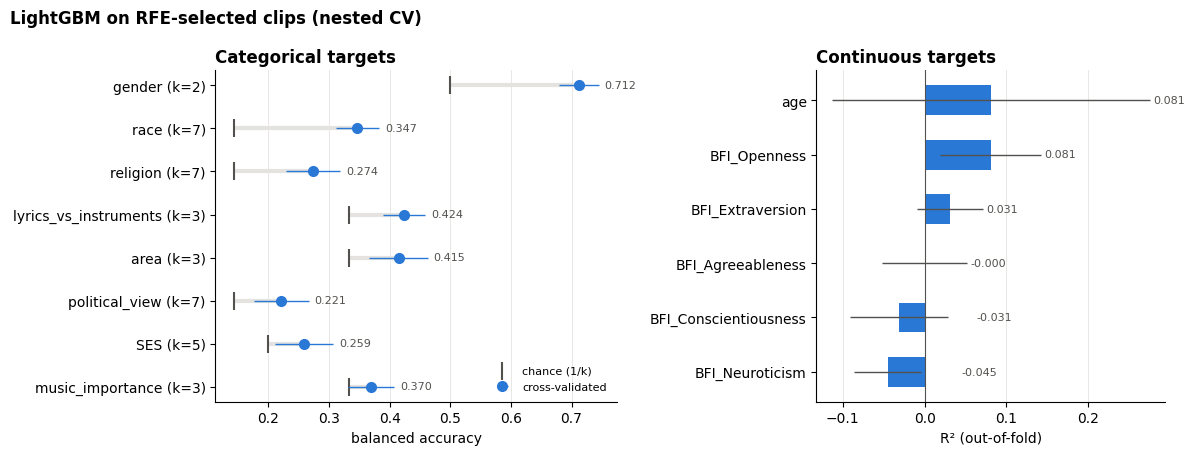

In [10]:
clf = results[results.metric == 'balanced accuracy'].sort_values('above_chance')
reg = results[results.metric == 'R2'].sort_values('score')
BLUE, INK2, GRID = '#2a78d6', '#52514e', '#e4e3df'

fig, ax = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={'width_ratios': [1.15, 1]})
y = np.arange(len(clf))
ax[0].hlines(y, clf.chance, clf.score, color=GRID, lw=3, zorder=1)
ax[0].scatter(clf.chance, y, marker='|', s=180, color=INK2, zorder=2, label='chance (1/k)')
ax[0].errorbar(clf.score, y, xerr=clf.sd, fmt='o', color=BLUE, ms=7, elinewidth=1, capsize=0,
               zorder=3, label='cross-validated')
for yi, (_, r) in zip(y, clf.iterrows()):
    ax[0].text(r.score + r.sd + 0.01, yi, f"{r.score:.3f}", va='center', fontsize=8, color=INK2)
ax[0].set_yticks(y); ax[0].set_yticklabels([f"{t} (k={int(k)})" for t, k in zip(clf.target, clf.k)])
ax[0].set_xlabel('balanced accuracy'); ax[0].set_title('Categorical targets', loc='left', fontweight='bold')
ax[0].legend(loc='lower right', frameon=False, fontsize=8)

y = np.arange(len(reg))
ax[1].axvline(0, color=INK2, lw=0.8)
ax[1].barh(y, reg.score, xerr=reg.sd, color=BLUE, height=0.55, error_kw=dict(lw=1, ecolor=INK2))
for yi, (_, r) in zip(y, reg.iterrows()):
    ax[1].text(max(r.score, 0) + r.sd + 0.004, yi, f"{r.score:.3f}", va='center', fontsize=8, color=INK2)
ax[1].set_yticks(y); ax[1].set_yticklabels(reg.target)
ax[1].set_xlabel('R² (out-of-fold)'); ax[1].set_title('Continuous targets', loc='left', fontweight='bold')

for a in ax:
    a.spines[['top', 'right']].set_visible(False); a.grid(axis='x', color=GRID, lw=0.6); a.set_axisbelow(True)
fig.suptitle('LightGBM on RFE-selected clips (nested CV)', x=0.01, ha='left', fontsize=12, fontweight='bold')
plt.tight_layout(); plt.show()

## 7. Final models: the same pipeline on all participants
RFE (static parameters) picks the clips from all 320, then Optuna tunes the final LightGBM on them. Each curve shows the
inner-CV score of the static RFE model at each clip count; the dot marks the count kept.

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 32 concurrent workers.


[Parallel(n_jobs=-1)]: Done   2 out of  14 | elapsed:   10.4s remaining:  1.0min


[Parallel(n_jobs=-1)]: Done   5 out of  14 | elapsed:   19.8s remaining:   35.8s


[Parallel(n_jobs=-1)]: Done   8 out of  14 | elapsed:   39.9s remaining:   29.9s


[Parallel(n_jobs=-1)]: Done  11 out of  14 | elapsed:  1.1min remaining:   18.6s


[Parallel(n_jobs=-1)]: Done  14 out of  14 | elapsed:  3.1min finished


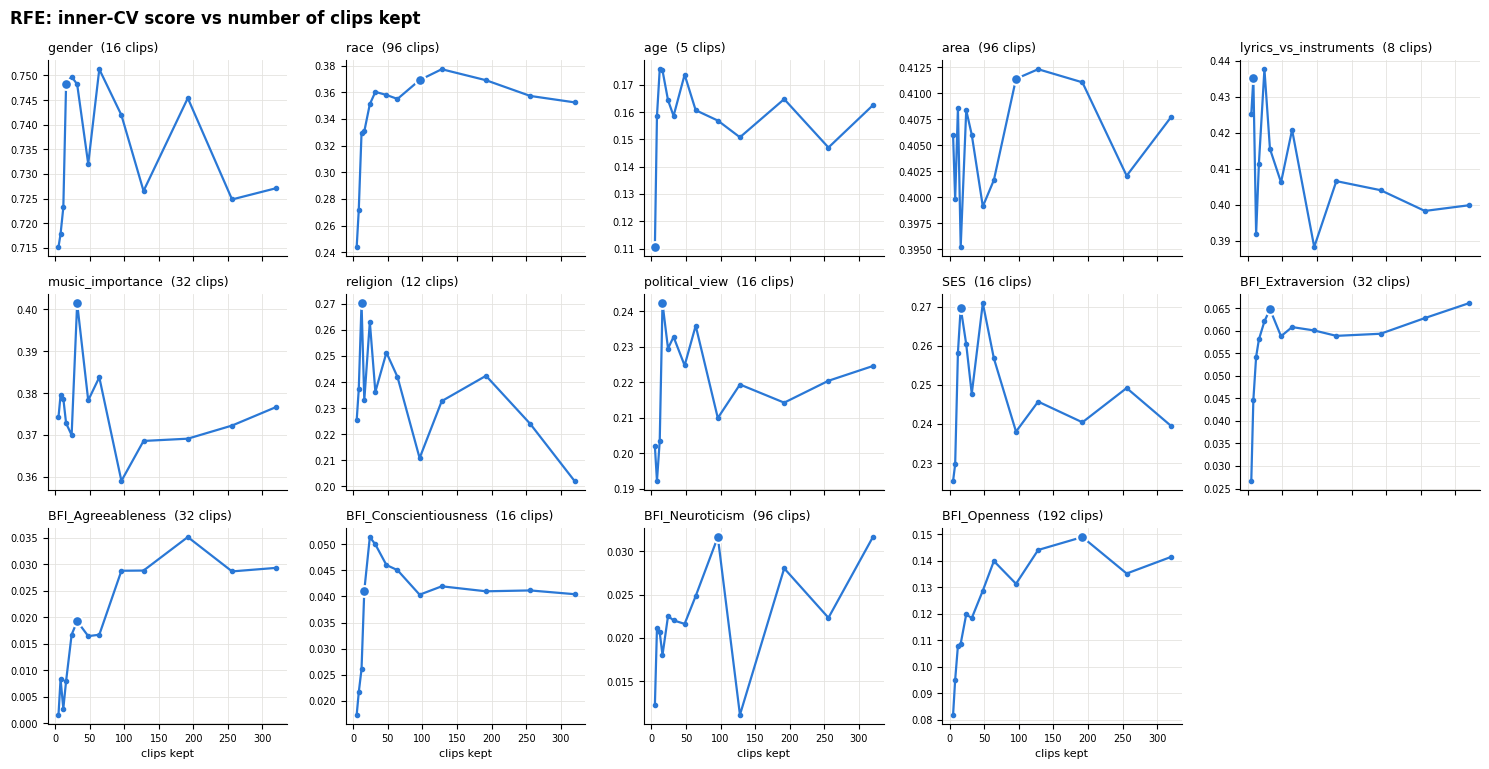

,learning_rate,num_leaves,min_child_samples,colsample_bytree,reg_lambda,n_trees,clips,inner_cv_score
gender,0.078942,43.0,89.0,0.312810,0.002836,236.0,16.0,0.780
race,0.023265,13.0,57.0,0.640578,0.108229,244.0,96.0,0.400
age,0.034262,6.0,5.0,0.997501,0.959189,122.0,5.0,0.311
area,0.010892,22.0,59.0,0.752075,1.303531,766.0,96.0,0.487
lyrics_vs_instruments,0.007607,40.0,66.0,0.578494,0.038561,834.0,8.0,0.524
music_importance,0.007877,4.0,7.0,0.813942,0.205814,1798.0,32.0,0.462
religion,0.014232,64.0,98.0,0.353049,1.221994,853.0,12.0,0.390
political_view,0.024989,4.0,27.0,0.301549,10.114508,562.0,16.0,0.335
SES,0.039775,4.0,22.0,0.788897,0.366530,169.0,16.0,0.347
BFI_Extraversion,0.007849,35.0,17.0,0.399450,0.202927,402.0,32.0,0.128


In [11]:
def fit_final(name):
    Xn, yn = DATA[name]
    return name, fit_pipeline(kinds[name], Xn, yn, target_seed(name))

final_models = dict(Parallel(n_jobs=OUTER_N_JOBS, verbose=5)(delayed(fit_final)(t) for t in targets))

names = list(targets)
ncol = 5; nrow = int(np.ceil(len(names) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(15, 2.6 * nrow), sharex=True, squeeze=False)
for a, name in zip(axes.flat, names):
    fit = final_models[name]
    counts, means = zip(*sorted(fit['curve'].items()))
    a.plot(counts, means, color=BLUE, lw=1.6, marker='o', ms=3)
    a.scatter([fit['count']], [fit['curve'][fit['count']]], color=BLUE, s=60, edgecolor='white',
              linewidth=1.5, zorder=3)
    a.set_title(f"{name}  ({fit['count']} clips)", fontsize=9, loc='left')
    a.spines[['top', 'right']].set_visible(False); a.grid(color=GRID, lw=0.6); a.set_axisbelow(True)
    a.tick_params(labelsize=7)
for a in list(axes.flat)[len(names):]:
    a.axis('off')
for a in axes[-1]:
    a.set_xlabel('clips kept', fontsize=8)
fig.suptitle('RFE: inner-CV score vs number of clips kept', x=0.01, ha='left', fontsize=12, fontweight='bold')
plt.tight_layout(); plt.show()

pd.DataFrame({t: {**f['params'], 'n_trees': f['n_trees'], 'clips': f['count'],
                  'inner_cv_score': round(f['inner_score'], 3)}
              for t, f in final_models.items()}).T

In [12]:
meta = pd.read_sql_query('''
    SELECT m.MusicId, m.Title, m.Artist, m.Year, g.Genre
    FROM music_meta m LEFT JOIN music_genre g ON m.GenreId = g.GenreId
''', conn).set_index('MusicId')

rows = []
for name, fit in final_models.items():
    clips = FEATURE_NAMES[fit['features']]
    imp = fit['model'].feature_importances_
    for clip, v in zip(clips, imp):
        rows.append(dict(target=name, MusicId=clip, importance=v))
selected = pd.DataFrame(rows).join(meta, on='MusicId')
selected['importance_share'] = selected.importance / selected.groupby('target').importance.transform('sum')
selected = selected.sort_values(['target', 'importance'], ascending=[True, False])

results['clips_selected_final'] = results.target.map({t: f['count'] for t, f in final_models.items()})
results[['target', 'metric', 'score', 'chance', 'clips_selected_median', 'clips_selected_range',
         'clips_selected_final']].round(3)

,target,metric,score,chance,clips_selected_median,clips_selected_range,clips_selected_final
0,gender,balanced accuracy,0.712,0.500,16.0,5-128,16
1,race,balanced accuracy,0.347,0.143,64.0,16-128,96
2,age,R2,0.081,0.000,16.0,5-128,5
3,area,balanced accuracy,0.415,0.333,16.0,5-256,96
4,lyrics_vs_instruments,balanced accuracy,0.424,0.333,12.0,5-32,8
5,music_importance,balanced accuracy,0.370,0.333,8.0,5-96,32
6,religion,balanced accuracy,0.274,0.143,8.0,5-32,12
7,political_view,balanced accuracy,0.221,0.143,48.0,5-320,16
8,SES,balanced accuracy,0.259,0.200,16.0,5-192,16
9,BFI_Extraversion,R2,0.031,0.000,24.0,5-96,32


In [13]:
# the most important selected clips for each target
for name in targets:
    top = selected[selected.target == name].head(8)
    print(f"\n=== {name}: {len(selected[selected.target == name])} clips selected ===")
    print(top[['importance_share', 'Title', 'Artist', 'Year', 'Genre']].round(3).to_string(index=False))


=== gender: 16 clips selected ===
 importance_share             Title          Artist  Year                       Genre
            0.122 Overworld (Zelda)      Koji Kondo  1986         World/International
            0.092            Tetris Alexey Pajitnov  1984         World/International
            0.092               "3"  Britney Spears  2009              Pop/Mainstream
            0.091      Bootylicious Destiny's Child  2001         R&B/Soul/Funk/Disco
            0.086          Iron Man   Black Sabbath  1970 Rock/Alternative/Metal/Punk
            0.082     Under the Sea Samuel E Wright  1989         World/International
            0.065     Lose Yourself          Eminem  2002                  Rap/Hiphop
            0.062  James Bond Theme    Monty Norman  1962         World/International

=== race: 96 clips selected ===
 importance_share                  Title                       Artist  Year               Genre
            0.055               Crow Hop          Black Lodge 

In [14]:
results.round(4).to_csv("music_prediction_results.csv", index=False)
selected.round(4).to_csv("music_prediction_selected_clips.csv", index=False)
print("saved music_prediction_results.csv and music_prediction_selected_clips.csv")

saved music_prediction_results.csv and music_prediction_selected_clips.csv


## 8. Diagnostics: where does performance break down?

Each subsection answers one question. All numbers use the **same outer folds** as section 5 and only
out-of-fold predictions, so nothing here is optimistic.

| § | Question | Look at |
|---|---|---|
| 8.1 | Is LightGBM the bottleneck, or is the signal just weak? | LightGBM vs. a regularized linear model on identical folds |
| 8.2 | How much signal is in the 320 clips at all? | best single-clip effect vs. its permutation null; # clips surviving FDR; Big Five reliability |
| 8.3 | Classification: which classes fail? | confusion matrices, per-class recall / precision / AUC vs. class size |
| 8.4 | Regression: why is R² low? | R² = r² − (r − SDratio)² − bias²; predicted vs. actual |
| 8.5 | Is the pipeline overfitting or unstable? | inner vs. outer score, fold spread, clip-selection agreement, tuned-setting spread |
| 8.6 | Would more participants help? | learning curves |
| 8.7 | One-table summary | all of the above, per target |

In [15]:
import scipy.stats as st
from sklearn.linear_model import LogisticRegressionCV, RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import f_classif
from sklearn.metrics import confusion_matrix, roc_auc_score

ORANGE = '#eb6834'
CLF_T = [t for t in targets if kinds[t] == 'clf']
REG_T = [t for t in targets if kinds[t] == 'reg']
RES = results.set_index('target')


def bh(p):
    """Benjamini-Hochberg q-values."""
    p = np.asarray(p, float); n = len(p); o = np.argsort(p)
    q = np.empty(n); q[o] = np.minimum.accumulate((p[o] * n / np.arange(1, n + 1))[::-1])[::-1]
    return np.minimum(q, 1)


def style(a, grid_axis='both'):
    a.spines[['top', 'right']].set_visible(False)
    a.grid(axis=grid_axis, color=GRID, lw=0.6); a.set_axisbelow(True)


def short(s, n=18):
    s = str(s); return s if len(s) <= n else s[:n - 1] + '…'


# out-of-fold predictions: one row per participant per repeat
OOF = {name: pd.concat([pd.DataFrame({'repeat': r.repeat, 'fold': r.fold, 'row': r.test_idx,
                                      'y': DATA[name][1][r.test_idx], 'pred': r.pred})
                        for r in d.itertuples()], ignore_index=True)
       for name, d in fold_results.groupby('target', sort=False)}
print(f"out-of-fold predictions for {len(OOF)} targets x {OUTER_REPEATS} repeats")

out-of-fold predictions for 14 targets x 3 repeats


### 8.1 Is LightGBM the bottleneck?
A class-balanced logistic regression (categorical) or ridge regression (continuous) on **all 320 clips**,
with its penalty tuned in an inner CV, is fit on exactly the same outer folds. Because the folds overlap,
a plain paired t-test is too liberal; `p_corrected` uses the Nadeau–Bengio corrected resampled t-test.

* LightGBM clearly **below** linear → the tree pipeline (RFE + small-sample tuning) is losing signal.
* Both close to chance → the clips carry little information about that target (see 8.2).

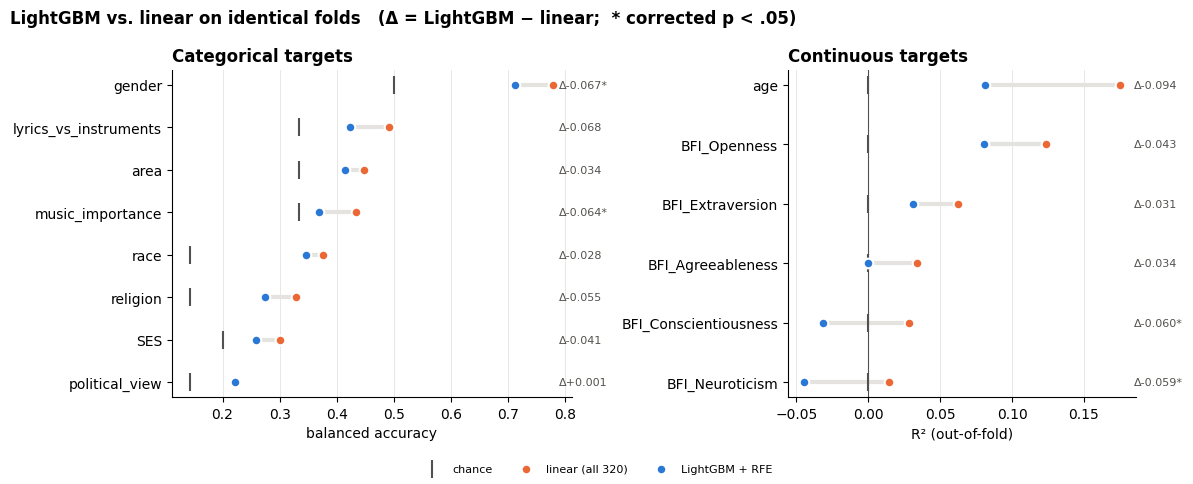

,target,metric,chance,lightgbm,linear,lgbm_minus_linear,lgbm_wins,t_corrected,p_corrected
0,gender,balanced accuracy,0.500,0.712,0.779,-0.067,0/15,-3.151,0.007
1,race,balanced accuracy,0.143,0.347,0.375,-0.028,3/15,-1.402,0.183
2,age,R2,0.000,0.081,0.175,-0.094,5/15,-0.776,0.450
3,area,balanced accuracy,0.333,0.415,0.448,-0.034,6/15,-0.930,0.368
4,lyrics_vs_instruments,balanced accuracy,0.333,0.424,0.491,-0.068,2/15,-2.083,0.056
5,music_importance,balanced accuracy,0.333,0.370,0.434,-0.064,1/15,-2.576,0.022
6,religion,balanced accuracy,0.143,0.274,0.329,-0.055,4/15,-1.149,0.270
7,political_view,balanced accuracy,0.143,0.221,0.221,0.001,9/15,0.023,0.982
8,SES,balanced accuracy,0.200,0.259,0.301,-0.041,5/15,-0.965,0.351
9,BFI_Extraversion,R2,0.000,0.031,0.062,-0.031,3/15,-1.314,0.210


In [16]:
def linear_model(kind):
    if kind == 'clf':
        return make_pipeline(StandardScaler(), LogisticRegressionCV(
            Cs=np.logspace(-4, 0, 9), cv=StratifiedKFold(3, shuffle=True, random_state=SEED),
            class_weight='balanced', scoring='balanced_accuracy', max_iter=3000))
    return make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-1, 5, 25)))


def linear_job(name, fold_id, tr, te):
    warnings.filterwarnings('ignore')          # workers do not inherit the notebook's warning filter
    Xn, yn = DATA[name]
    m = linear_model(kinds[name]).fit(Xn[tr], yn[tr])
    return dict(target=name, repeat=fold_id // OUTER_SPLITS + 1, fold=fold_id % OUTER_SPLITS + 1,
                linear=score_fn(kinds[name])(yn[te], m.predict(Xn[te])))


def corrected_t(d, test_frac=1 / OUTER_SPLITS):
    """Nadeau & Bengio (2003) corrected resampled t-test for overlapping CV folds."""
    J = len(d)
    t = d.mean() / np.sqrt((1 / J + test_frac / (1 - test_frac)) * d.var(ddof=1))
    return t, 2 * st.t.sf(abs(t), J - 1)


lin = pd.DataFrame(Parallel(n_jobs=-1)(
    delayed(linear_job)(name, i, tr, te)
    for name in targets for i, (tr, te) in enumerate(outer_folds(name, DATA[name][1]))))
paired = fold_results[['target', 'repeat', 'fold', 'score']].merge(lin, on=['target', 'repeat', 'fold'])

rows = []
for name, d in paired.groupby('target', sort=False):
    diff = (d.score - d.linear).to_numpy()
    t, p = corrected_t(diff)
    rows.append(dict(target=name, metric=RES.metric[name], chance=RES.chance[name],
                     lightgbm=d.score.mean(), linear=d.linear.mean(), lgbm_minus_linear=diff.mean(),
                     lgbm_wins=f"{(diff > 0).sum()}/{len(diff)}", t_corrected=t, p_corrected=p))
baseline = pd.DataFrame(rows)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={'width_ratios': [1.15, 1]})
for a, sub, xlabel in [(ax[0], baseline[baseline.metric != 'R2'], 'balanced accuracy'),
                       (ax[1], baseline[baseline.metric == 'R2'], 'R² (out-of-fold)')]:
    sub = sub.sort_values('linear'); y = np.arange(len(sub))
    a.hlines(y, sub[['lightgbm', 'linear']].min(1), sub[['lightgbm', 'linear']].max(1), color=GRID, lw=3, zorder=1)
    a.scatter(sub.chance, y, marker='|', s=180, color=INK2, zorder=2, label='chance')
    a.scatter(sub.linear, y, s=48, color=ORANGE, edgecolor='white', linewidth=1.5, zorder=3, label='linear (all 320)')
    a.scatter(sub.lightgbm, y, s=48, color=BLUE, edgecolor='white', linewidth=1.5, zorder=4, label='LightGBM + RFE')
    for yi, (_, r) in zip(y, sub.iterrows()):
        mark = '*' if r.p_corrected < 0.05 else ''
        a.text(sub[['lightgbm', 'linear']].to_numpy().max() + 0.01, yi, f"Δ{r.lgbm_minus_linear:+.3f}{mark}",
               va='center', fontsize=8, color=INK2)
    a.set_yticks(y); a.set_yticklabels(sub.target); a.set_xlabel(xlabel); style(a, 'x')
ax[0].set_title('Categorical targets', loc='left', fontweight='bold')
ax[1].set_title('Continuous targets', loc='left', fontweight='bold'); ax[1].axvline(0, color=INK2, lw=0.8)
fig.legend(*ax[0].get_legend_handles_labels(), loc='lower center', ncol=3, frameon=False, fontsize=8)
fig.suptitle('LightGBM vs. linear on identical folds   (Δ = LightGBM − linear;  * corrected p < .05)',
             x=0.01, ha='left', fontsize=12, fontweight='bold')
plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()
baseline.round(3)

### 8.2 How much signal is in the clips?
Descriptive, on all participants (not used for any model). For every clip: its association with the target
(r² for continuous targets, η² from one-way ANOVA for categorical). `best_clip` is the strongest single clip;
`best_clip_null` is what the strongest clip looks like when the target is **shuffled** (mean of 50 shuffles).
If `best_clip` is barely above its null, no single clip is informative and any signal must be spread thinly.
`clips_q05` counts clips surviving Benjamini–Hochberg FDR (by chance ≈ 0); `clips_p05` would be ≈ 16 by chance.

For the Big Five, Cronbach's α bounds what is predictable: the observed score is only α "true score", so
even a perfect model of the trait could not exceed R² ≈ α.

In [17]:
def cronbach(items):
    d = items.dropna(); k = d.shape[1]
    return k / (k - 1) * (1 - d.var(ddof=1).sum() / d.sum(axis=1).var(ddof=1))


def univariate(name, n_null=50):
    Xn, yn = DATA[name]
    rng = np.random.default_rng(SEED)
    n = len(yn)
    if kinds[name] == 'clf':
        k = len(np.unique(yn))
        def effect(y):
            F, p = f_classif(Xn, y)
            return F * (k - 1) / (F * (k - 1) + n - k), p          # eta^2 per clip
    else:
        Xz = (Xn - Xn.mean(0)) / Xn.std(0)
        def effect(y):
            r = Xz.T @ ((y - y.mean()) / y.std()) / n
            t = r * np.sqrt((n - 2) / (1 - r ** 2))
            return r ** 2, 2 * st.t.sf(np.abs(t), n - 2)          # r^2 per clip
    e, p = effect(yn)
    null_best = np.mean([effect(rng.permutation(yn))[0].max() for _ in range(n_null)])
    top = np.argsort(e)[::-1][:3]
    return dict(target=name, effect='eta2' if kinds[name] == 'clf' else 'r2',
                best_clip=e.max(), best_clip_null=null_best, best_over_null=e.max() / null_best,
                clips_q05=int((bh(p) < 0.05).sum()), clips_p05=int((p < 0.05).sum()),
                top3_clips=', '.join(str(X.columns[i]) for i in top))


signal = pd.DataFrame([univariate(t) for t in targets])
alpha = {f'BFI_{s}': cronbach(bfi.loc[bfi.index.intersection(X.index), it]) for s, it in SCALES.items()}
signal['reliability_alpha'] = signal.target.map(alpha)
signal.round(4)

,target,effect,best_clip,best_clip_null,best_over_null,clips_q05,clips_p05,top3_clips,reliability_alpha
0,gender,eta2,0.0808,0.0118,6.8384,182,189,"320, 319, 309",NaN
1,race,eta2,0.1736,0.0258,6.7261,240,247,"282, 160, 73",NaN
2,age,r2,0.0453,0.0108,4.2046,72,111,"101, 117, 140",NaN
3,area,eta2,0.0485,0.0155,3.1300,82,122,"248, 20, 28",NaN
4,lyrics_vs_instruments,eta2,0.0568,0.0155,3.6757,177,204,"120, 58, 175",NaN
5,music_importance,eta2,0.0345,0.0149,2.3140,48,115,"257, 181, 191",NaN
6,religion,eta2,0.0799,0.0250,3.1931,160,195,"302, 160, 276",NaN
7,political_view,eta2,0.0836,0.0249,3.3547,214,224,"276, 71, 103",NaN
8,SES,eta2,0.0457,0.0212,2.1595,18,89,"68, 6, 282",NaN
9,BFI_Extraversion,r2,0.0447,0.0088,5.0639,180,201,"107, 108, 109",0.8473


### 8.3 Classification: which classes fail?
Confusion matrices pool the out-of-fold predictions of all repeats and are **row-normalized** (each row = the
true class, cells = where those people were predicted to go). Balanced accuracy is the mean of the diagonal,
so one small class the model never finds pulls the whole score down.

`auc_ovr` is one-vs-rest AUC per class, computed inside each test fold and averaged. It is threshold-free:
a class with AUC well above 0.5 but low recall has ranking signal that the argmax decision is not using.

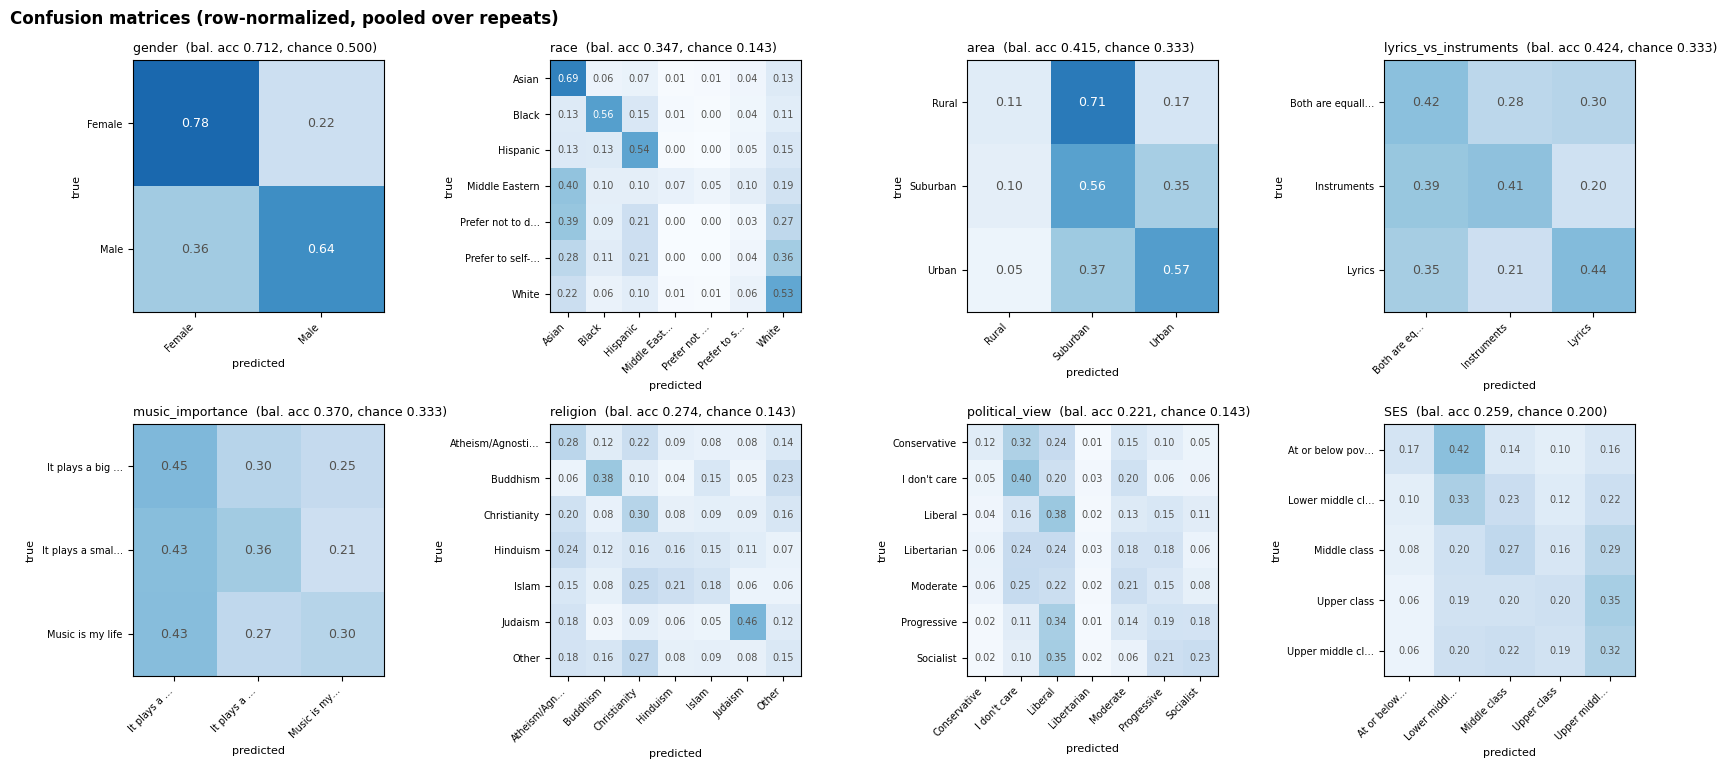

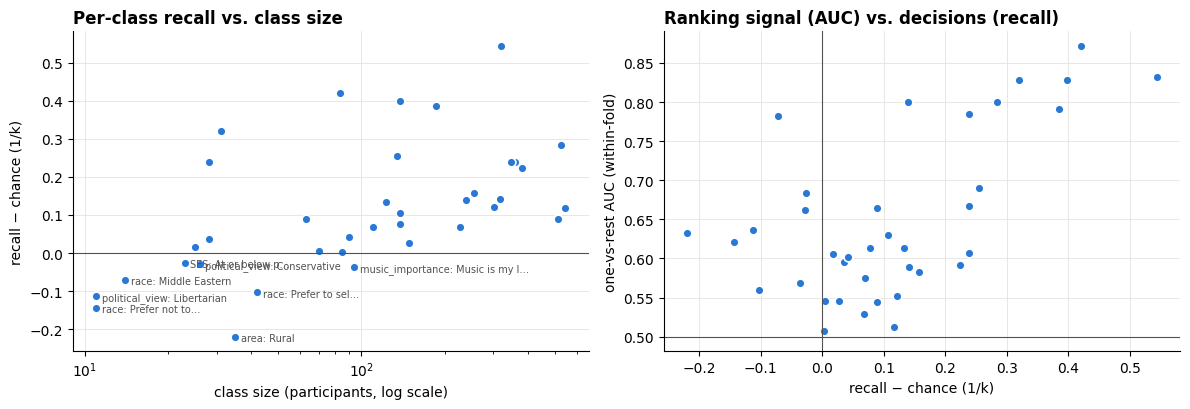

,target,cls,n,share,recall,precision,f1,chance_recall,auc_ovr,recall_over_chance
0,gender,Female,527,0.688,0.784,0.828,0.805,0.500,0.800,0.284
1,gender,Male,239,0.312,0.640,0.574,0.605,0.500,0.800,0.140
2,race,Asian,319,0.402,0.687,0.705,0.696,0.143,0.832,0.544
3,race,Black,84,0.106,0.563,0.463,0.508,0.143,0.872,0.421
4,race,Hispanic,138,0.174,0.541,0.528,0.535,0.143,0.828,0.398
5,race,Middle Eastern,14,0.018,0.071,0.150,0.097,0.143,0.782,-0.071
6,race,Prefer not to disclose,11,0.014,0.000,0.000,0.000,0.143,0.620,-0.143
7,race,Prefer to self-describe,42,0.053,0.040,0.044,0.042,0.143,0.560,-0.103
8,race,White,186,0.234,0.529,0.520,0.524,0.143,0.791,0.386
9,area,Rural,35,0.045,0.114,0.067,0.085,0.333,0.632,-0.219


In [18]:
cls_rows = []
fig_n = len(CLF_T); ncol = 4; nrow = int(np.ceil(fig_n / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4.2 * ncol, 3.9 * nrow), squeeze=False)
for a, name in zip(axes.flat, CLF_T):
    o, names = OOF[name], CLASSES[name]
    k = len(names)
    cm = confusion_matrix(o.y, o.pred, labels=range(k))
    cmn = cm / cm.sum(1, keepdims=True)
    im = a.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
    for i in range(k):
        for j in range(k):
            a.text(j, i, f"{cmn[i, j]:.2f}", ha='center', va='center', fontsize=7 if k > 4 else 9,
                   color='white' if cmn[i, j] > 0.55 else INK2)
    a.set_xticks(range(k)); a.set_xticklabels([short(c, 12) for c in names], rotation=45, ha='right', fontsize=7)
    a.set_yticks(range(k)); a.set_yticklabels([short(c, 16) for c in names], fontsize=7)
    a.set_xlabel('predicted', fontsize=8); a.set_ylabel('true', fontsize=8)
    a.set_title(f"{name}  (bal. acc {RES.score[name]:.3f}, chance {1 / k:.3f})", fontsize=9, loc='left')

    # per-class metrics
    d = fold_results[fold_results.target == name]
    yn = DATA[name][1]
    auc = {c: [] for c in range(k)}
    for r in d.itertuples():
        yt = yn[r.test_idx]
        for c in range(k):
            pos = (yt == c)
            if 0 < pos.sum() < len(pos):
                auc[c].append(roc_auc_score(pos, r.proba[:, c]))
    n_people = np.bincount(yn, minlength=k)
    for c in range(k):
        tp = cm[c, c]; recall = tp / cm[c].sum(); precision = tp / cm[:, c].sum() if cm[:, c].sum() else np.nan
        cls_rows.append(dict(target=name, cls=names[c], n=int(n_people[c]), share=n_people[c] / len(yn),
                             recall=recall, precision=precision,
                             f1=2 * precision * recall / (precision + recall) if precision + recall else 0,
                             chance_recall=1 / k, auc_ovr=np.mean(auc[c]) if auc[c] else np.nan))
for a in list(axes.flat)[fig_n:]:
    a.axis('off')
fig.suptitle('Confusion matrices (row-normalized, pooled over repeats)', x=0.01, ha='left', fontsize=12, fontweight='bold')
plt.tight_layout(); plt.show()

per_class = pd.DataFrame(cls_rows)
per_class['recall_over_chance'] = per_class.recall - per_class.chance_recall

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].axhline(0, color=INK2, lw=0.8)
ax[0].scatter(per_class.n, per_class.recall_over_chance, s=40, color=BLUE, edgecolor='white', linewidth=1.2)
for _, r in per_class[per_class.recall_over_chance < 0].iterrows():
    ax[0].annotate(f"{r.target}: {short(r.cls, 14)}", (r.n, r.recall_over_chance), fontsize=7, color=INK2,
                   xytext=(4, -3), textcoords='offset points')
ax[0].set_xscale('log'); ax[0].set_xlabel('class size (participants, log scale)'); ax[0].set_ylabel('recall − chance (1/k)')
ax[0].set_title('Per-class recall vs. class size', loc='left', fontweight='bold'); style(ax[0])
ax[1].axhline(0.5, color=INK2, lw=0.8); ax[1].axvline(0, color=INK2, lw=0.8)
ax[1].scatter(per_class.recall_over_chance, per_class.auc_ovr, s=40, color=BLUE, edgecolor='white', linewidth=1.2)
ax[1].set_xlabel('recall − chance (1/k)'); ax[1].set_ylabel('one-vs-rest AUC (within-fold)')
ax[1].set_title('Ranking signal (AUC) vs. decisions (recall)', loc='left', fontweight='bold'); style(ax[1])
plt.tight_layout(); plt.show()
per_class.round(3)

### 8.4 Regression: why is R² low?
For pooled out-of-fold predictions, R² splits exactly into three parts (Murphy, 1988):

**R² = r² − (r − SD_pred / SD_y)² − ((mean_pred − mean_y) / SD_y)²**

* `r2` – how well predictions **rank** people (the ceiling for R² given this correlation).
* `loss_conditional_bias` – lost because predictions are too spread out or too compressed relative to r.
  `sd_ratio` > r means predictions are over-dispersed (overconfident); `calib_slope` < 1 says the same.
* `loss_mean_bias` – lost because predictions are shifted on average (usually ~0).

A low `r` means little ranking signal; a decent `r` with a large `loss_conditional_bias` means the model
finds the right ordering but scales it badly. In the plots, the blue dots are mean predictions within
deciles of the true score: a flat line = no signal; a line steeper than the dashed identity = overconfident.

R² here is computed on predictions **pooled** across the folds of a repeat, so it can differ from the section 6
score, which averages per-fold R². A big gap means one or two folds are very bad, e.g. for age a fold that
happens to contain several of the few participants over 30. The age line below shows how much of the error,
and of the signal, comes from those participants: if R² within age ≤ 30 is near or below 0, the model mostly
separates older participants from the students rather than predicting age within the student range.

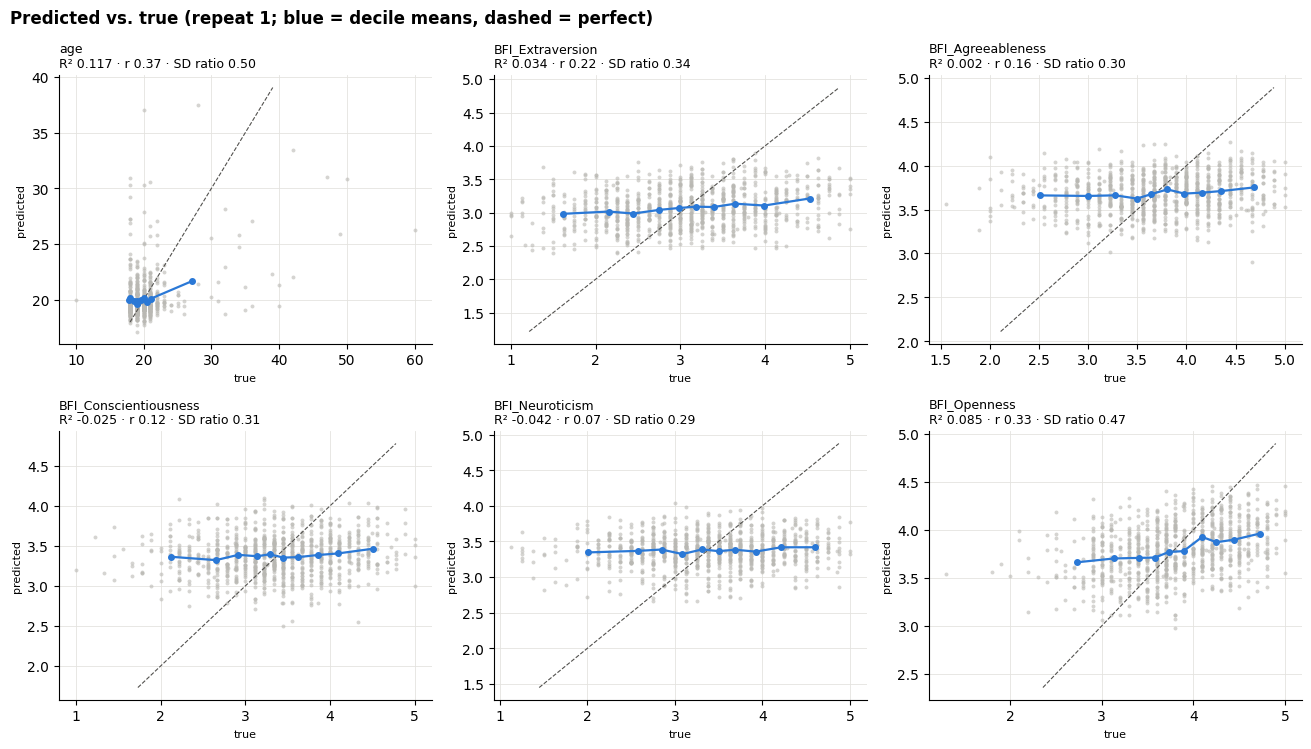

age: 20 participants over 30 of 796; R² all = 0.117, R² age ≤ 30 only = -0.840; share of squared error from the over-30s = 60%


,target,R2,r,r2,sd_ratio,calib_slope,loss_conditional_bias,loss_mean_bias,spearman,check_R2
0,age,0.1169,0.3694,0.1392,0.4960,0.7540,0.0222,0.0001,0.1546,0.1169
1,BFI_Extraversion,0.0343,0.2231,0.0499,0.3449,0.6494,0.0155,0.0000,0.2154,0.0343
2,BFI_Agreeableness,0.0022,0.1597,0.0266,0.3042,0.5386,0.0244,0.0000,0.1691,0.0022
3,BFI_Conscientiousness,-0.0255,0.1193,0.0143,0.3112,0.3941,0.0396,0.0002,0.1255,-0.0255
4,BFI_Neuroticism,-0.0417,0.0712,0.0054,0.2874,0.2479,0.0471,0.0000,0.0626,-0.0417
5,BFI_Openness,0.0854,0.3270,0.1072,0.4721,0.6935,0.0216,0.0002,0.3294,0.0854


In [19]:
def decompose(y, p):
    sy, sp = y.std(), p.std()
    r = np.corrcoef(y, p)[0, 1]
    return dict(R2=1 - ((y - p) ** 2).mean() / y.var(), r=r, r2=r ** 2, sd_ratio=sp / sy,
                calib_slope=np.cov(y, p, ddof=0)[0, 1] / p.var(),
                loss_conditional_bias=(r - sp / sy) ** 2, loss_mean_bias=((p.mean() - y.mean()) / sy) ** 2,
                spearman=st.spearmanr(y, p)[0])

reg_diag = (pd.DataFrame([dict(target=name, repeat=rep, **decompose(g.y.to_numpy(float), g.pred.to_numpy(float)))
                          for name in REG_T for rep, g in OOF[name].groupby('repeat')])
            .groupby('target', sort=False).mean().drop(columns='repeat').reset_index())
reg_diag['check_R2'] = reg_diag.r2 - reg_diag.loss_conditional_bias - reg_diag.loss_mean_bias

ncol = 3; nrow = int(np.ceil(len(REG_T) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4.4 * ncol, 3.8 * nrow), squeeze=False)
for a, name in zip(axes.flat, REG_T):
    g = OOF[name][OOF[name].repeat == 1]
    a.scatter(g.y, g.pred, s=8, color='#b9b8b3', alpha=0.6, linewidth=0)
    lo, hi = np.percentile(np.r_[g.y, g.pred], [0.5, 99.5])
    a.plot([lo, hi], [lo, hi], '--', color=INK2, lw=0.8)
    dec = g.assign(bin=pd.qcut(g.y.rank(method='first'), 10, labels=False)).groupby('bin')[['y', 'pred']].mean()
    a.plot(dec.y, dec.pred, '-o', color=BLUE, ms=4, lw=1.6)
    rd = reg_diag.set_index('target').loc[name]
    a.set_title(f"{name}\nR² {rd.R2:.3f} · r {rd.r:.2f} · SD ratio {rd.sd_ratio:.2f}", fontsize=9, loc='left')
    a.set_xlabel('true', fontsize=8); a.set_ylabel('predicted', fontsize=8); style(a)
for a in list(axes.flat)[len(REG_T):]:
    a.axis('off')
fig.suptitle('Predicted vs. true (repeat 1; blue = decile means, dashed = perfect)', x=0.01, ha='left',
             fontsize=12, fontweight='bold')
plt.tight_layout(); plt.show()

if 'age' in OOF:
    g = OOF['age']
    old = g.y > 30
    print(f"age: {int(old.sum() / OUTER_REPEATS)} participants over 30 of {int(len(g) / OUTER_REPEATS)}; "
          f"R² all = {1 - ((g.y - g.pred) ** 2).sum() / ((g.y - g.y.mean()) ** 2).sum():.3f}, "
          f"R² age ≤ 30 only = {1 - ((g.y[~old] - g.pred[~old]) ** 2).sum() / ((g.y[~old] - g.y[~old].mean()) ** 2).sum():.3f}; "
          f"share of squared error from the over-30s = {((g.y[old] - g.pred[old]) ** 2).sum() / ((g.y - g.pred) ** 2).sum():.0%}")
reg_diag.round(4)

### 8.5 Overfitting and stability
* `optimism` = inner-CV score (what tuning saw) − outer score (honest). A large gap means the selection and
  tuning are fitting noise in the training folds.
* `fold_sd` = spread of the outer score across the 15 folds.
* `jaccard` = average overlap of the selected clip sets between folds (1 = identical), next to what two
  **random** sets of the same sizes would share. Near the random value → selection is essentially noise.
* Wide ranges of tuned `learning_rate` / `num_leaves` across folds mean the tuning surface is flat or noisy.

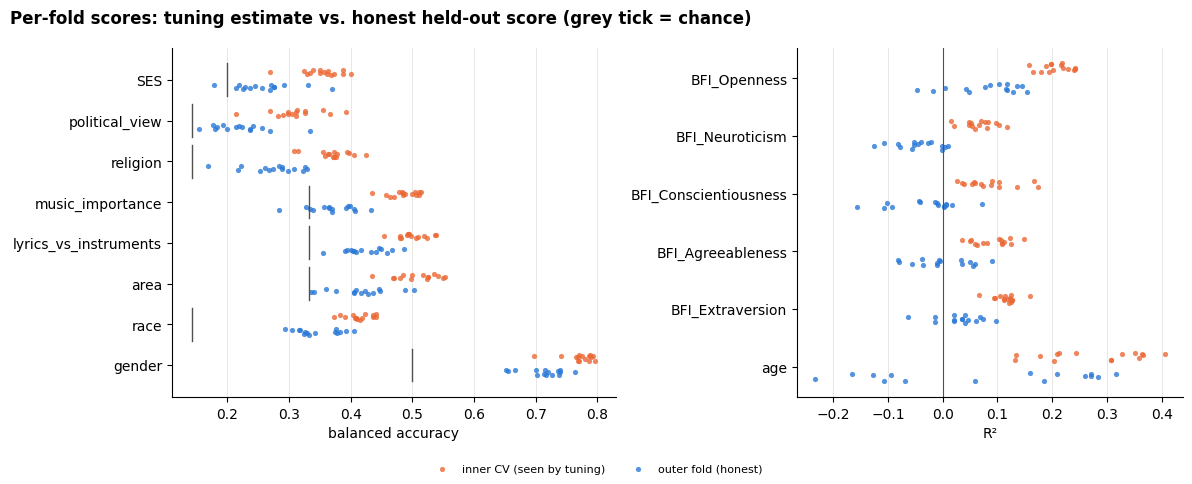

,target,outer,inner,optimism,fold_sd,fold_min,fold_max,clips_median,jaccard,jaccard_random,lr_range,leaves_range,trees_range
0,gender,0.712,0.772,0.059,0.032,0.652,0.764,16.0,0.319,0.032,0.005–0.193,4–58,23–2611
1,race,0.347,0.413,0.067,0.035,0.294,0.406,64.0,0.263,0.094,0.005–0.198,4–37,29–1527
2,age,0.081,0.273,0.192,0.194,-0.234,0.316,16.0,0.172,0.029,0.008–0.139,4–63,63–2388
3,area,0.415,0.507,0.092,0.048,0.335,0.503,16.0,0.127,0.061,0.006–0.185,4–62,61–1972
4,lyrics_vs_instruments,0.424,0.500,0.076,0.035,0.355,0.487,12.0,0.123,0.016,0.011–0.152,4–61,18–492
5,music_importance,0.370,0.486,0.117,0.038,0.284,0.434,8.0,0.098,0.016,0.006–0.176,4–48,41–2099
6,religion,0.274,0.371,0.097,0.045,0.168,0.330,8.0,0.191,0.014,0.006–0.189,4–61,27–4138
7,political_view,0.221,0.311,0.089,0.045,0.154,0.335,48.0,0.160,0.079,0.005–0.175,4–57,32–4408
8,SES,0.259,0.353,0.094,0.048,0.178,0.369,16.0,0.111,0.034,0.009–0.188,4–51,33–1471
9,BFI_Extraversion,0.031,0.115,0.084,0.040,-0.064,0.097,24.0,0.145,0.036,0.005–0.150,4–64,19–601


In [20]:
stab = []
for name, d in fold_results.groupby('target', sort=False):
    masks = np.stack(d.selected_mask.to_numpy()); J, p = masks.shape
    obs, rnd = [], []
    for i in range(J):
        for j in range(i + 1, J):
            a_, b_ = masks[i].sum(), masks[j].sum(); inter = (masks[i] & masks[j]).sum()
            obs.append(inter / (a_ + b_ - inter)); e = a_ * b_ / p; rnd.append(e / (a_ + b_ - e))
    bp = pd.DataFrame(list(d.best_params))
    stab.append(dict(target=name, outer=d.score.mean(), inner=d.inner_cv_score.mean(),
                     optimism=(d.inner_cv_score - d.score).mean(), fold_sd=d.score.std(),
                     fold_min=d.score.min(), fold_max=d.score.max(),
                     clips_median=d.n_selected.median(), jaccard=np.mean(obs), jaccard_random=np.mean(rnd),
                     lr_range=f"{bp.learning_rate.min():.3f}–{bp.learning_rate.max():.3f}",
                     leaves_range=f"{bp.num_leaves.min()}–{bp.num_leaves.max()}",
                     trees_range=f"{d.n_trees.min()}–{d.n_trees.max()}"))
stab = pd.DataFrame(stab)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={'width_ratios': [1.15, 1]})
for a, names_, xlabel in [(ax[0], CLF_T, 'balanced accuracy'), (ax[1], REG_T, 'R²')]:
    for yi, name in enumerate(names_):
        d = fold_results[fold_results.target == name]
        jit = np.random.default_rng(yi).uniform(-0.15, 0.15, len(d))
        a.scatter(d.inner_cv_score, yi + 0.18 + jit * 0.5, s=14, color=ORANGE, alpha=0.8, linewidth=0,
                  label='inner CV (seen by tuning)' if yi == 0 else None)
        a.scatter(d.score, yi - 0.18 + jit * 0.5, s=14, color=BLUE, alpha=0.8, linewidth=0,
                  label='outer fold (honest)' if yi == 0 else None)
        if kinds[name] == 'clf':
            a.plot([RES.chance[name]] * 2, [yi - 0.4, yi + 0.4], color=INK2, lw=1)
    a.set_yticks(range(len(names_))); a.set_yticklabels(names_); a.set_xlabel(xlabel); style(a, 'x')
ax[1].axvline(0, color=INK2, lw=0.8)
fig.legend(*ax[0].get_legend_handles_labels(), loc='lower center', ncol=2, frameon=False, fontsize=8)
fig.suptitle('Per-fold scores: tuning estimate vs. honest held-out score (grey tick = chance)',
             x=0.01, ha='left', fontsize=12, fontweight='bold')
plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()
stab.round(3)

In [21]:
# clips selected most consistently across outer folds (a stable core would show frequencies near 1)
if 'meta' in globals():
    for name in targets:
        top = (selection_frequency[selection_frequency.target == name].head(5)
               .join(meta[['Title', 'Artist', 'Genre']], on='clip'))
        print(f"\n{name}:  " + " | ".join(f"{r.selection_frequency:.0%} {short(r.Title, 24)} ({short(r.Genre, 14)})"
                                          for r in top.itertuples()))


gender:  100% Bootylicious (R&B/Soul/Funk…) | 100% James Bond Theme (World/Interna…) | 100% Tetris (World/Interna…) | 100% Overworld (Zelda) (World/Interna…) | 93% "3" (Pop/Mainstream)

race:  100% What You Won't Do For L… (R&B/Soul/Funk…) | 100% Foolish (R&B/Soul/Funk…) | 100% El Son de la Negra (World/Interna…) | 100% Guantanamera (World/Interna…) | 100% Song With Didgeridoo (World/Interna…)

age:  93% Take Me to Church (Rock/Alternat…) | 93% You Can't Hurry Love (R&B/Soul/Funk…) | 73% Rockstar (Rap/Hiphop) | 67% Gin and Juice (Rap/Hiphop) | 60% Beauiful People (Rock/Alternat…)

area:  93% Every Rose Has Its Thorn (Rock/Alternat…) | 80% Happy (Pop/Mainstream) | 73% Texas Tornado (Country/Folk) | 73% All The Small Things (Pop/Mainstream) | 67% I Believe (R&B/Soul/Funk…)

lyrics_vs_instruments:  73% Song With Didgeridoo (World/Interna…) | 53% Perfect (Rock/Alternat…) | 53% Blue In Green (Jazz/Vocal) | 53% The Rite Of Spring (Classical/Ope…) | 40% Gucci Gang (Rap/Hiphop)

music_importa

### 8.6 Would more participants help?
Each model is refit on 40–100% of every outer training fold (repeat 1) and scored on the untouched test fold.
To keep this fast, LightGBM here uses the fixed RFE settings on all 320 clips with early stopping (no RFE or
Optuna), next to the linear model. **A curve still rising at 100%** means performance is sample-size limited;
**a flat curve** means more of the same data will not help.

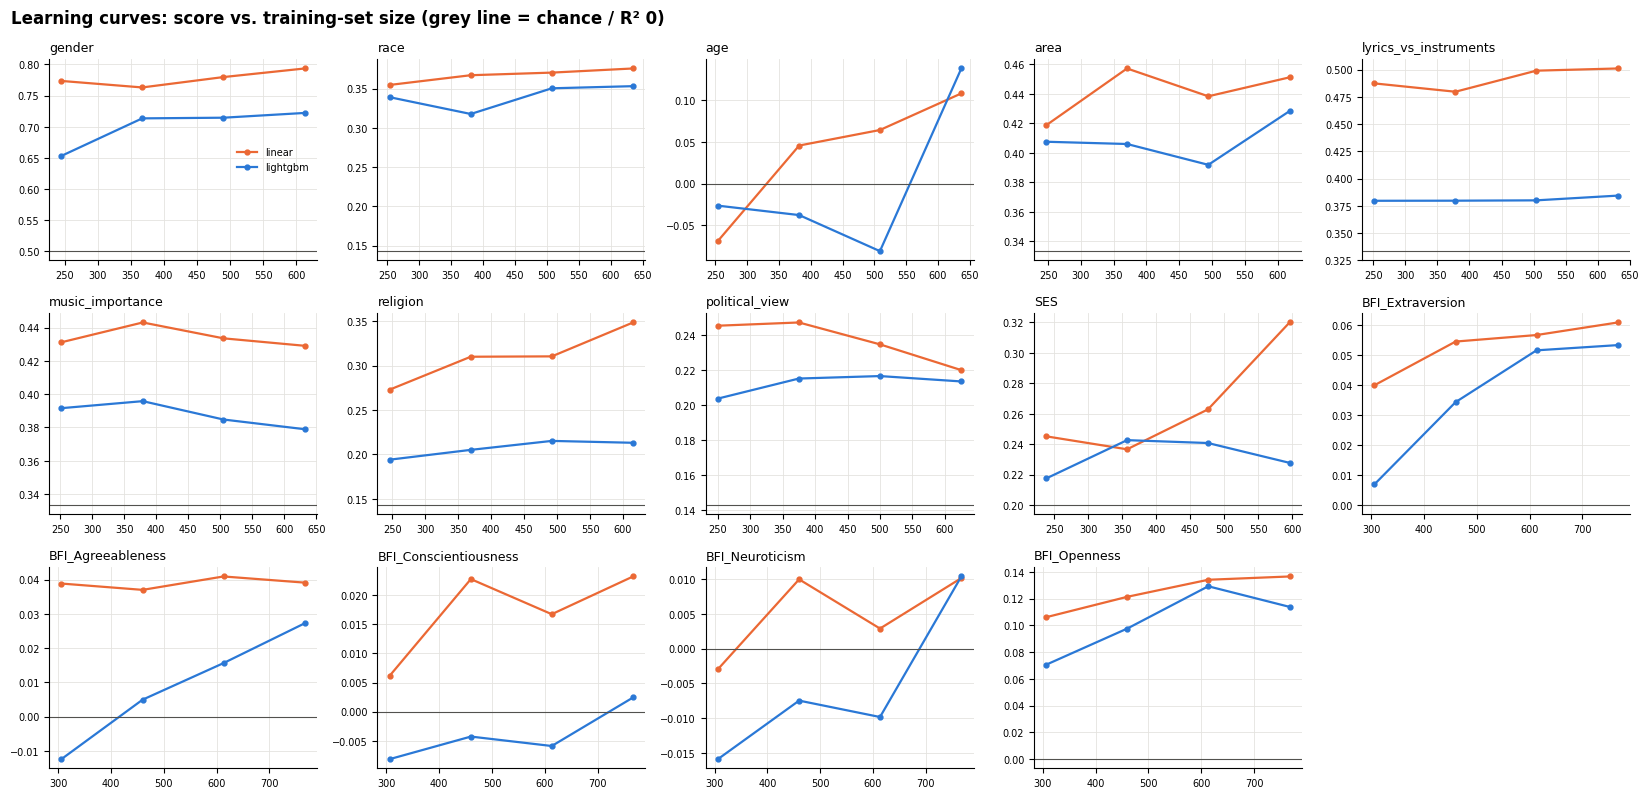

,target,gain_last20pct_linear,gain_last20pct_lightgbm
0,BFI_Agreeableness,-0.0018,0.0116
1,BFI_Conscientiousness,0.0065,0.0083
2,BFI_Extraversion,0.0042,0.0017
3,BFI_Neuroticism,0.0072,0.0202
4,BFI_Openness,0.0025,-0.0154
5,SES,0.0570,-0.0130
6,age,0.0438,0.2187
7,area,0.0128,0.0364
8,gender,0.0138,0.0077
9,lyrics_vs_instruments,0.0020,0.0043


In [22]:
FRACS = [0.4, 0.6, 0.8, 1.0]

def lc_job(name, fold_id, tr, te, frac, model):
    warnings.filterwarnings('ignore')
    Xn, yn = DATA[name]; kind = kinds[name]; seed = SEED + fold_id
    strat = (lambda idx: yn[idx]) if kind == 'clf' else (lambda idx: None)
    try:
        if frac < 1:
            tr, _ = train_test_split(tr, train_size=frac, random_state=seed, stratify=strat(tr))
        if model == 'linear':
            pred = linear_model(kind).fit(Xn[tr], yn[tr]).predict(Xn[te])
        else:
            a, b = train_test_split(tr, test_size=ES_HOLDOUT, random_state=seed, stratify=strat(tr))
            pred = fit_es(kind, RFE_PARAMS, seed, Xn[a], yn[a], Xn[b], yn[b]).predict(Xn[te])
        score = score_fn(kind)(yn[te], pred)
    except ValueError:                      # a tiny class can make a stratified split impossible
        score = np.nan
    return dict(target=name, frac=frac, n_train=len(tr), model=model, score=score)

lc_jobs = [(name, i, tr, te, f, m)
           for name in targets
           for i, (tr, te) in enumerate(list(outer_folds(name, DATA[name][1]))[:OUTER_SPLITS])
           for f in FRACS for m in ('linear', 'lightgbm')]
lc = (pd.DataFrame(Parallel(n_jobs=-1)(delayed(lc_job)(*j) for j in lc_jobs))
        .groupby(['target', 'model', 'frac'], sort=False).agg(n_train=('n_train', 'mean'), score=('score', 'mean'))
        .reset_index())

ncol = 5; nrow = int(np.ceil(len(targets) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(3.3 * ncol, 2.7 * nrow), squeeze=False)
for a, name in zip(axes.flat, targets):
    for model, color in [('linear', ORANGE), ('lightgbm', BLUE)]:
        g = lc[(lc.target == name) & (lc.model == model)]
        a.plot(g.n_train, g.score, '-o', color=color, ms=3.5, lw=1.6, label=model)
    ref = RES.chance[name]
    a.axhline(ref, color=INK2, lw=0.8)
    a.set_title(name, fontsize=9, loc='left'); a.tick_params(labelsize=7); style(a)
for a in list(axes.flat)[len(targets):]:
    a.axis('off')
axes[0, 0].legend(frameon=False, fontsize=7)
fig.suptitle('Learning curves: score vs. training-set size (grey line = chance / R² 0)', x=0.01, ha='left',
             fontsize=12, fontweight='bold')
plt.tight_layout(); plt.show()

lc_gain = (lc.pivot_table(index='target', columns=['model', 'frac'], values='score')
             .pipe(lambda t: pd.DataFrame({m: t[(m, 1.0)] - t[(m, 0.8)] for m in ('linear', 'lightgbm')}))
             .add_prefix('gain_last20pct_').reset_index())
lc_gain.round(4)

### 8.7 Summary
One row per target. Reading it left to right: how far above chance the model is, whether a linear model does
better, whether any single clip carries real signal, whether the pipeline overfits or selects clips
inconsistently, whether the problem is concentrated in small classes / miscalibrated regression, and whether
more data would help.

In [23]:
cls_summary = (per_class.groupby('target')
               .apply(lambda d: pd.Series({'smallest_class_n': d.n.min(),
                                           'worst_class': d.loc[d.recall_over_chance.idxmin(), 'cls'],
                                           'worst_recall_over_chance': d.recall_over_chance.min(),
                                           'mean_auc_ovr': d.auc_ovr.mean()}))
               .reset_index())
summary = (results[['target', 'metric', 'score', 'chance', 'above_chance']]
           .merge(baseline[['target', 'linear', 'lgbm_minus_linear', 'p_corrected']], on='target')
           .merge(signal[['target', 'best_over_null', 'clips_q05', 'reliability_alpha']], on='target')
           .merge(stab[['target', 'optimism', 'fold_sd', 'jaccard', 'jaccard_random']], on='target')
           .merge(cls_summary, on='target', how='left')
           .merge(reg_diag[['target', 'r', 'sd_ratio', 'loss_conditional_bias']], on='target', how='left')
           .merge(lc_gain, on='target', how='left'))
summary.to_csv("music_prediction_diagnostics.csv", index=False)
per_class.to_csv("music_prediction_per_class.csv", index=False)
print("saved music_prediction_diagnostics.csv and music_prediction_per_class.csv")
summary.round(3)

saved music_prediction_diagnostics.csv and music_prediction_per_class.csv


,target,metric,score,chance,above_chance,linear,lgbm_minus_linear,p_corrected,best_over_null,clips_q05,...,jaccard_random,smallest_class_n,worst_class,worst_recall_over_chance,mean_auc_ovr,r,sd_ratio,loss_conditional_bias,gain_last20pct_linear,gain_last20pct_lightgbm
0,gender,balanced accuracy,0.712,0.500,0.212,0.779,-0.067,0.007,6.838,182,...,0.032,239.0,Male,0.140,0.800,NaN,NaN,NaN,0.014,0.008
1,race,balanced accuracy,0.347,0.143,0.204,0.375,-0.028,0.183,6.726,240,...,0.094,11.0,Prefer not to disclose,-0.143,0.755,NaN,NaN,NaN,0.005,0.003
2,age,R2,0.081,0.000,0.081,0.175,-0.094,0.450,4.205,72,...,0.029,NaN,NaN,NaN,NaN,0.369,0.496,0.022,0.044,0.219
3,area,balanced accuracy,0.415,0.333,0.081,0.448,-0.034,0.368,3.130,82,...,0.061,35.0,Rural,-0.219,0.630,NaN,NaN,NaN,0.013,0.036
4,lyrics_vs_instruments,balanced accuracy,0.424,0.333,0.091,0.491,-0.068,0.056,3.676,177,...,0.016,138.0,Instruments,0.077,0.596,NaN,NaN,NaN,0.002,0.004
5,music_importance,balanced accuracy,0.370,0.333,0.036,0.434,-0.064,0.022,2.314,48,...,0.016,94.0,Music is my life,-0.035,0.542,NaN,NaN,NaN,-0.004,-0.006
6,religion,balanced accuracy,0.274,0.143,0.131,0.329,-0.055,0.270,3.193,160,...,0.014,25.0,Other,0.002,0.642,NaN,NaN,NaN,0.038,-0.002
7,political_view,balanced accuracy,0.221,0.143,0.078,0.221,0.001,0.982,3.355,214,...,0.079,11.0,Libertarian,-0.113,0.634,NaN,NaN,NaN,-0.015,-0.003
8,SES,balanced accuracy,0.259,0.200,0.059,0.301,-0.041,0.351,2.159,18,...,0.034,23.0,At or below poverty line,-0.026,0.584,NaN,NaN,NaN,0.057,-0.013
9,BFI_Extraversion,R2,0.031,0.000,0.031,0.062,-0.031,0.210,5.064,180,...,0.036,NaN,NaN,NaN,NaN,0.223,0.345,0.016,0.004,0.002
